# Feature extraction

In [15]:
from pathlib import Path
import pandas as pd
import numpy as np
import librosa
import librosa.display
import ipywidgets as widgets
from IPython.display import display
from IPython.display import Audio
from scipy.fft import dct
import matplotlib.pyplot as plt
import audb, audformat, audeer  # for EmoDB database
import os

## <font color="orange"> Read and extract metadata from filenames <font>

In [16]:
# Download and load all audio files and tables
db = audb.load("emodb", version="2.0.0", full_path=True, verbose=True)

# Combine 'files' (with speaker metadata) and 'emotion' tables
df = audformat.utils.concat([
    db["files"].get(map={"speaker": ["speaker", "gender", "age"]}),
    db["emotion"].get(),
])

# View
df.head()

Get:   emodb v2.0.0
Cache: /home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b


,duration,transcription,speaker,gender,age,emotion,emotion.confidence,emotion.naturalness
file,,,,,,,,
/home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b/wav/03a01Fa.wav,0 days 00:00:01.898250000,a01,3,male,31,happiness,0.90,0.75
/home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b/wav/03a01Nc.wav,0 days 00:00:01.611250000,a01,3,male,31,neutral,1.00,0.95
/home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b/wav/03a01Wa.wav,0 days 00:00:01.877812500,a01,3,male,31,anger,0.95,0.90
/home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b/wav/03a02Fc.wav,0 days 00:00:02.006250000,a02,3,male,31,happiness,0.85,0.60
/home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b/wav/03a02Nc.wav,0 days 00:00:01.439812500,a02,3,male,31,neutral,1.00,0.95


In [17]:
# Filter to keep only high-confidence, natural recordings
confidence_threshold = 0.7
naturalness_threshold = 0.5
clean_df = df[(df["emotion.confidence"] > confidence_threshold) 
            & (df["emotion.naturalness"] > naturalness_threshold)].reset_index()
print(f"Kept {len(clean_df)} out of {len(df)} samples.")

Kept 567 out of 816 samples.


## <font color="orange"> MFCCs feature extraction <font>

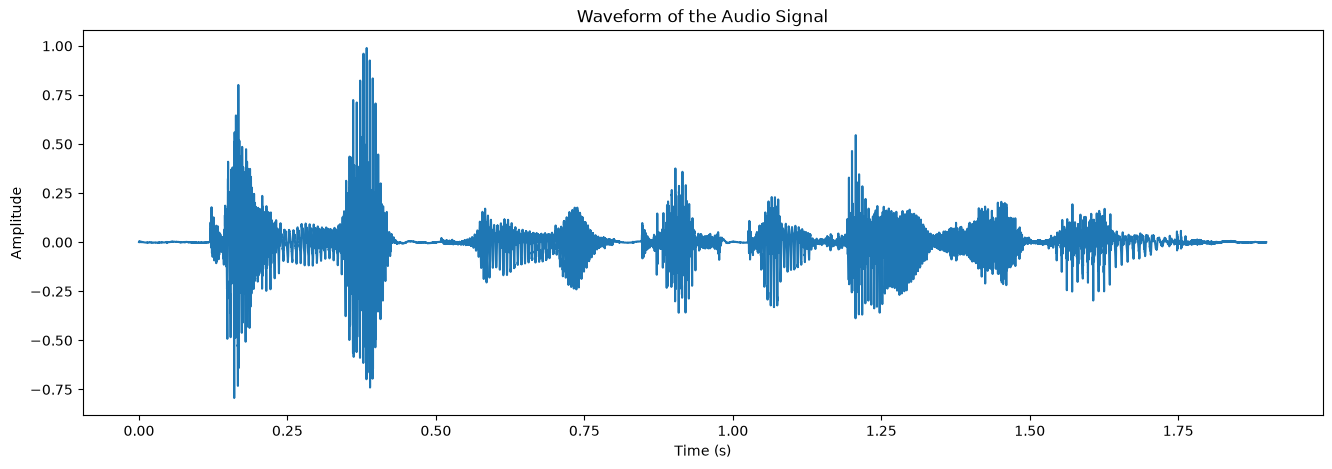

In [18]:
# just to visualize a audio signal
y, sr = librosa.load(clean_df["file"][0])

# Plot the waveform
t = np.arange(len(y)) / sr
plt.figure(figsize=(16, 5))
plt.plot(t,y)
plt.title('Waveform of the Audio Signal')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()



### **Predefined constant factors**

In [19]:
# pre-emphasis factor
alpha = 0.96  # default standard

# framing parameters
frame_size = 0.025 # each frame (windows) is 25 ms long
frame_stride = 0.01 # the window moves forward 10 ms each time

# Mel filter bank params
nfilt = 40 # number of filters

## dct
num_ceps = 40 # number of cepstral coefficients, a bit detail for emotion recognition

### **Signal pre-emphasis**

{22050}


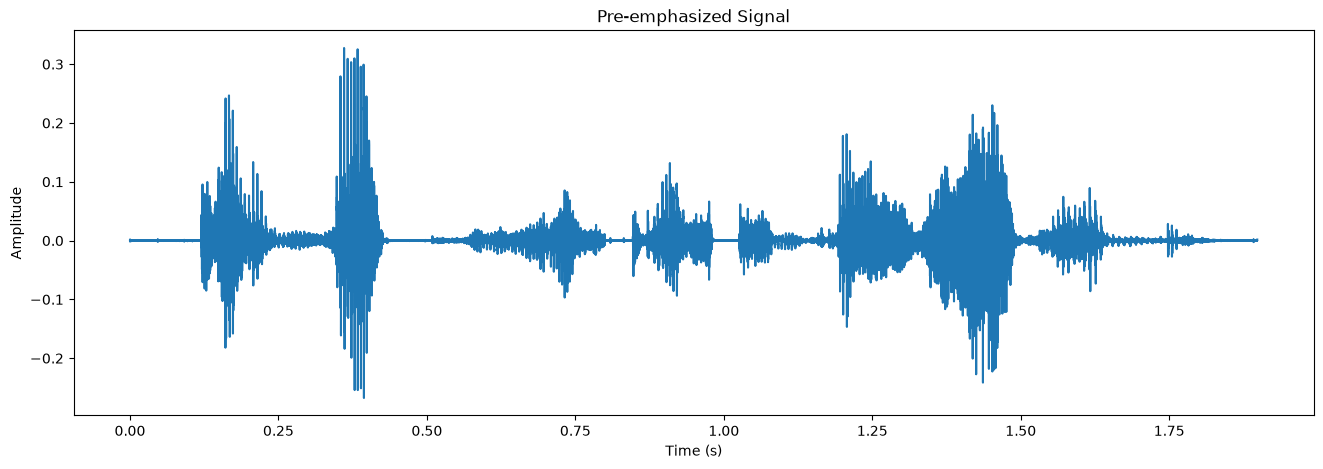

In [20]:
y_origin = []
y_preemphasis = []
sr_list = []

# apply filter for each audio signal
for audio_file in clean_df["file"]:
    # read signal and sample rate (samples/second ; Hz)
    y, sr = librosa.load(audio_file)
    y_preemp = np.append(y[0], y[1:] - alpha*y[:-1])
    y_origin.append(y)
    y_preemphasis.append(y_preemp)
    sr_list.append(sr) 

# plot one result for visualization
print(set(sr_list))
t = np.arange(len(y_preemphasis[0])) / sr_list[0]
plt.figure(figsize=(16, 5))
plt.plot(t, y_preemphasis[0])
plt.title('Pre-emphasized Signal')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()




### **Framing: partitioning signal**

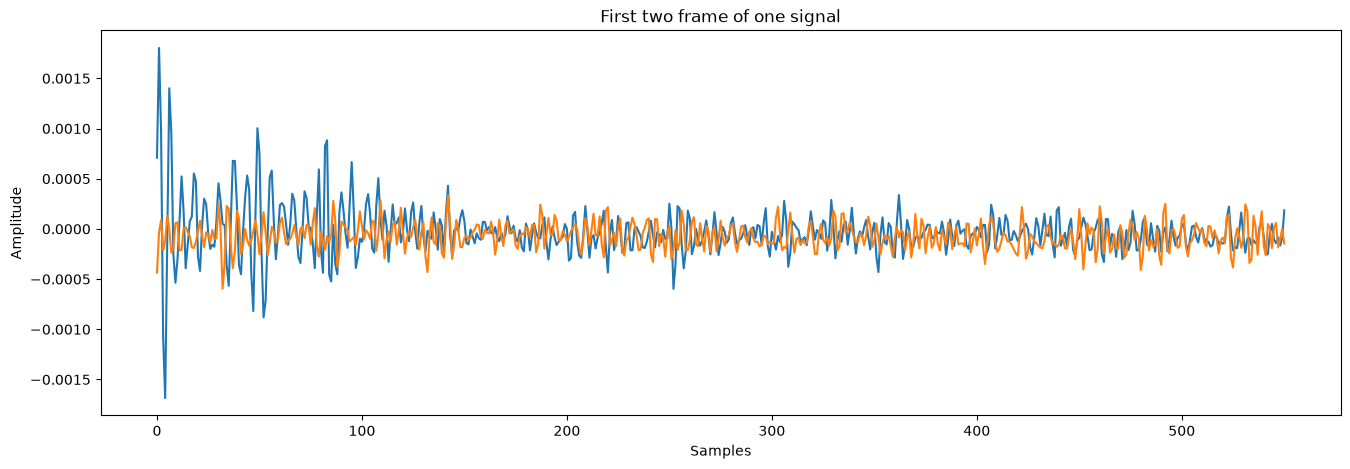

In [21]:
# Convert frame params from seconds to samples (keep integer)
sr = sr_list[0] # signal rates are the same among all signals
frame_length, frame_step = frame_size * sr, frame_stride * sr  
frame_length = int(round(frame_length))
frame_step = int(round(frame_step))

frames = []
for yp in y_preemphasis:
    # calculate number of frames
    signal_length = len(yp)
    num_frames = int(np.ceil(float(np.abs(signal_length - frame_length)) / frame_step))
    
    # pad signal to ensure every frame has the same number of samples
    pad_length = num_frames * frame_step + frame_length
    pad_signal = np.append(yp, np.zeros(pad_length - signal_length))
    
    # slice into frames
    indices = (np.tile(np.arange(0, frame_length), (num_frames,1)) 
        + np.tile(np.arange(0, num_frames * frame_step, frame_step), (frame_length, 1)).T )
    frames.append(pad_signal[indices])

# plot two frames for visualization    
plt.figure(figsize=(16, 5))
plt.plot(frames[0][0])
plt.plot(frames[0][1])
plt.title('First two frame of one signal')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()


### **Windowing : applying window (tapering) function**

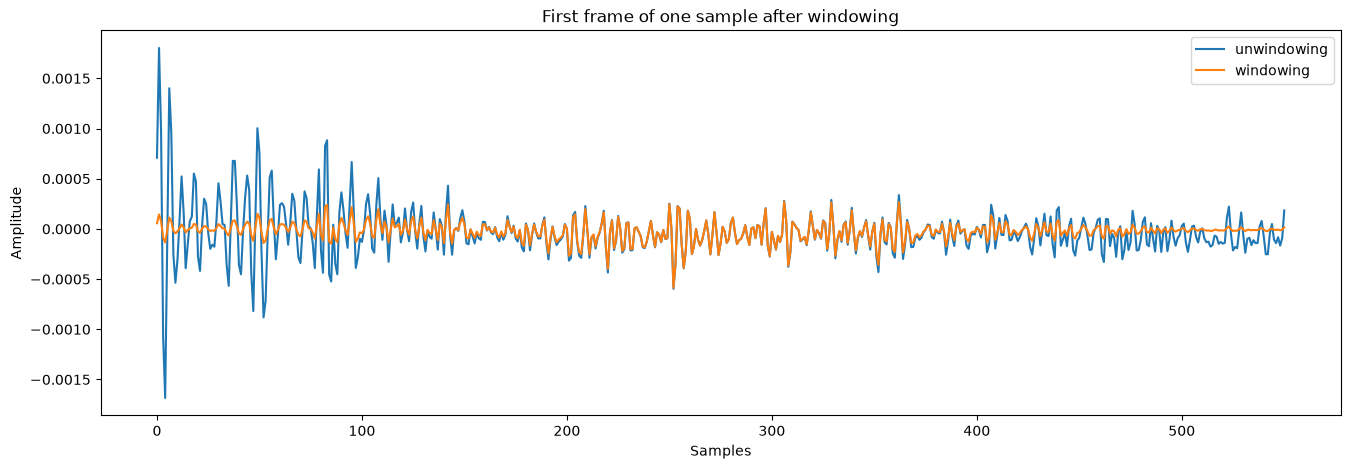

In [22]:
# apply Hamming
windowing_frames = []
for fr in frames:
    windowing_frames.append(fr * np.hamming(frame_length))

# visualization
plt.figure(figsize=(16, 5))
plt.plot(frames[0][0], label="unwindowing")
plt.plot(windowing_frames[0][0], label="windowing")
plt.title('First frame of one sample after windowing')
plt.legend(loc="best")
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()

### **Fast Fourier Transform (FFT)**


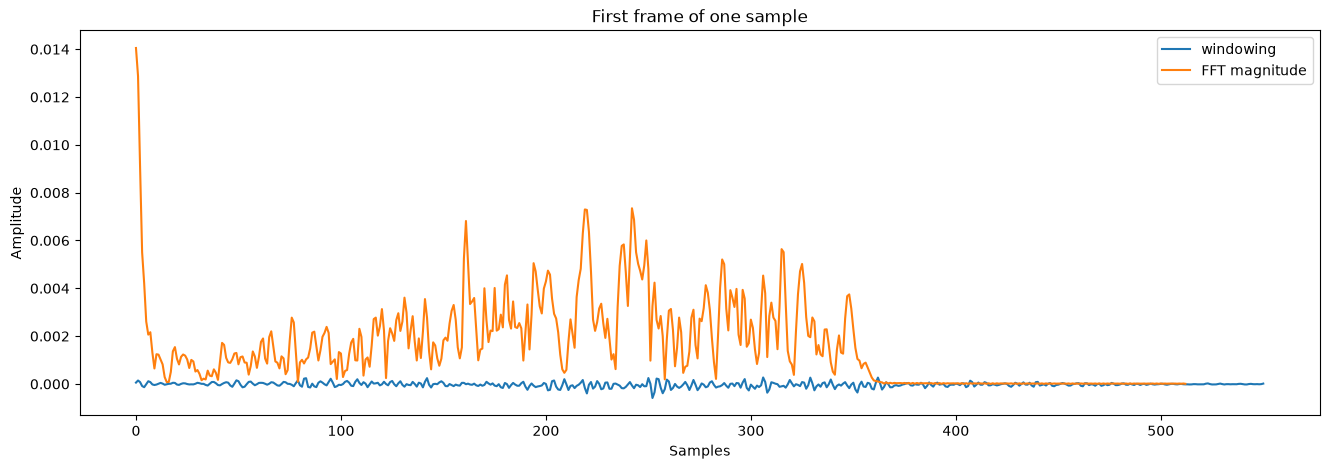

In [23]:
NFFT = 1024 # FFT size for sr = 22050
fft_frames = []
pow_fft_frames = []
for fr in windowing_frames:
    tmp = np.absolute(np.fft.rfft(fr, NFFT))
    fft_frames.append(tmp) # magnitude of FFT
    pow_fft_frames.append((1.0/NFFT)*(tmp**2)) # power spectrum ~ magnitude^2

# visualization
plt.figure(figsize=(16, 5))
plt.plot(windowing_frames[0][0], label="windowing")
plt.plot(fft_frames[0][0], label="FFT magnitude")
plt.title('First frame of one sample')
plt.legend(loc="best")
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()

### **Mel filter bank**

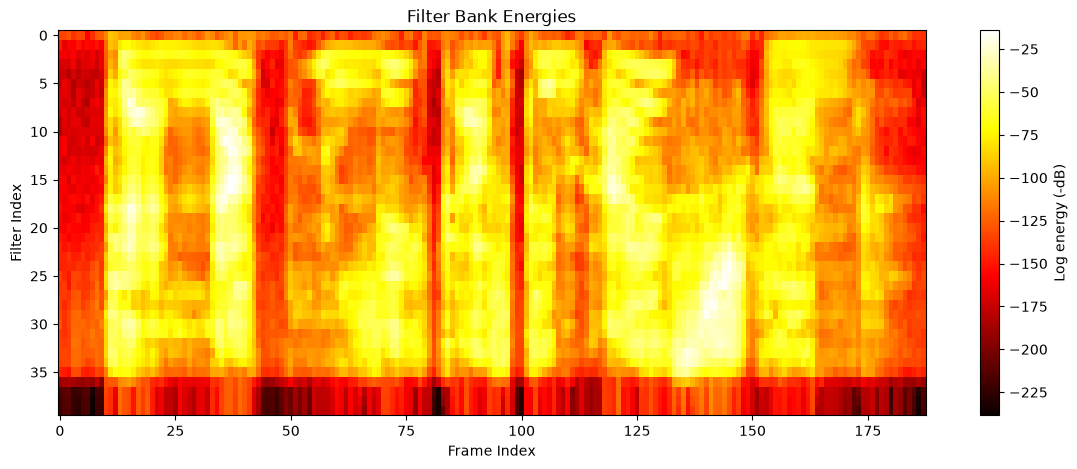

In [24]:
# set up the triangular filters: same for all frames
## convert Hz to Mel
low_freq_mel = 0 # 0 Hz maps to 0 mel
high_freq_mel = 2595 * np.log10(1 + (sr / 2) / 700)
## equally spacing in Mel scale
mel_points = np.linspace(low_freq_mel, high_freq_mel, nfilt + 2)
## convert Mel to Hz 
hz_points = 700 * (10 ** (mel_points / 2595) - 1)  
bin = np.floor((NFFT + 1) * hz_points / sr)

fbank = np.zeros((nfilt, int(np.floor(NFFT / 2 + 1))))
for m in range(1, nfilt + 1):
    f_m_minus = int(bin[m - 1])   # left
    f_m = int(bin[m])             # center
    f_m_plus = int(bin[m + 1])    # right

    for k in range(f_m_minus, f_m):
        fbank[m - 1, k] = (k - bin[m - 1]) / (bin[m] - bin[m - 1])
    for k in range(f_m, f_m_plus):
        fbank[m - 1, k] = (bin[m + 1] - k) / (bin[m + 1] - bin[m])
    
# now, apply filter to each frame
filter_banks = []
for fr in pow_fft_frames:
    tmp = np.dot(fr, fbank.T) 
    # for numerical stability: avoid log(0) in the next calculation
    tmp = np.where(tmp == 0, np.finfo(float).eps, tmp)  
    # convert to deciben (minus dB)
    filter_banks.append(20 * np.log10(tmp))

# Plot the filter bank energies
plt.figure(figsize=(14, 5))
plt.imshow(filter_banks[0].T, cmap='hot', aspect='auto')
plt.colorbar(label='Log energy (-dB)')
plt.title('Filter Bank Energies')
plt.xlabel('Frame Index')
plt.ylabel('Filter Index')
plt.show()

### **Discrete Cosine Transform (DCT)**

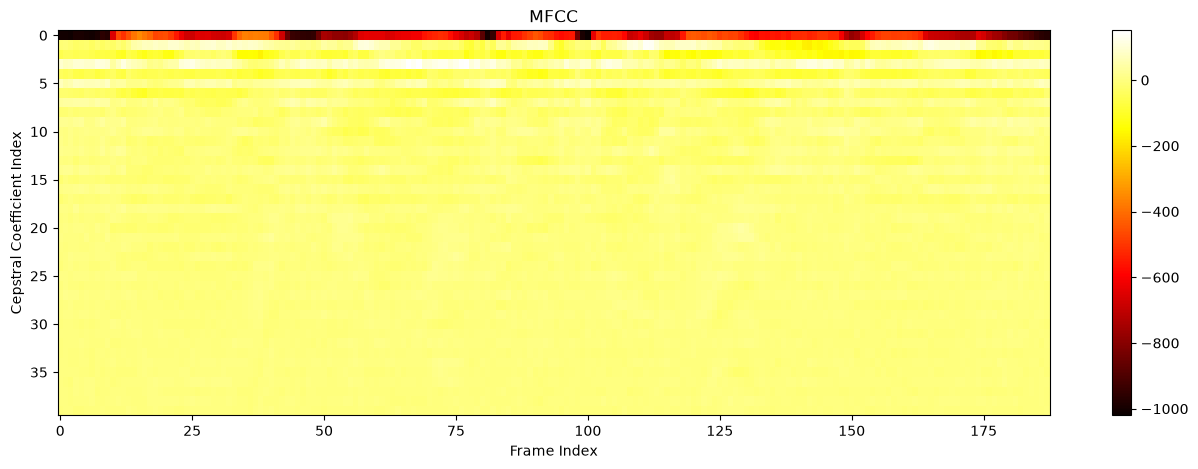

In [25]:
# now time to extract mfcc
mfccs = []
mean_mfccs = []
for i, fb in enumerate(filter_banks):
    mfcc = dct(fb, type=2, axis=1, norm='ortho')[:, :num_ceps]
    mfccs.append(mfcc)
    from pathlib import Path

    path = clean_df["file"][i]
    name = Path(path).stem
    pd.DataFrame(mfcc).to_csv(f"../data/extraction/mfcc_mat/{name}.csv", index=False)
    

# Plot the MFCCs
plt.figure(figsize=(16, 5))
plt.imshow(mfccs[0].T, cmap='hot', aspect='auto')
plt.colorbar()
plt.title('MFCC')
plt.xlabel('Frame Index')
plt.ylabel('Cepstral Coefficient Index')
plt.show()

### **Save mean and std of mfcc to csv**

In [26]:
# calculate delta mfccs
def calculate_delta_mfcc(mfcc, width=9, order=1):
    """Calculate MFCC delta features for an array shaped (frames, coefficients)."""
    mfcc = np.asarray(mfcc)

    if mfcc.ndim != 2 or mfcc.shape[0] < 3:
        raise ValueError("mfcc must be 2D and contain at least 3 frames")

    # librosa requires an odd width of at least 3, no larger than the frame count
    width = min(width, mfcc.shape[0] if mfcc.shape[0] % 2 else mfcc.shape[0] - 1)
    if width < 3:
        raise ValueError("At least 3 frames are required to calculate deltas")

    return librosa.feature.delta(mfcc, width=width, order=order, axis=0)

delta_mfccs = [calculate_delta_mfcc(mfcc) for mfcc in mfccs]

In [30]:
# save mean and std MFCCs
mfcc_means_list = []
mfcc_stds_list = []
delta_mfcc_means_list = []
delta_mfcc_stds_list = []
for i, mfcc in enumerate(mfccs):
    mfcc_means_list.append(np.mean(mfcc, axis=0))
    mfcc_stds_list.append(np.std(mfcc, axis=0))
    delta_mfcc_means_list.append(np.mean(delta_mfccs[i], axis=0))
    delta_mfcc_stds_list.append(np.std(delta_mfccs[i], axis=0))

mfcc_means = np.array(mfcc_means_list)
mfcc_stds = np.array(mfcc_stds_list)
delta_means = np.array(delta_mfcc_means_list)
delta_stds = np.array(delta_mfcc_stds_list)

n_mfcc = mfcc_means.shape[1]

def to_df(arr, prefix):
    return pd.DataFrame(arr, columns=[f"{prefix}{k+1}" for k in range(n_mfcc)], index=clean_df.index)

df = pd.concat([
    clean_df,
    to_df(mfcc_means, "mfcc_mean_"),
    to_df(mfcc_stds, "mfcc_std_"),
    to_df(delta_means, "delta_mean_"),
    to_df(delta_stds, "delta_std_"),
], axis=1)

df.to_csv("../data/extraction/meta_mean_std_mfcc.csv", index=False)

